# 📊 Exploratory Data Analysis (EDA) Operasional & Penyiapan Dataset AI — Ale's Place Cipoho

**Tim Capstone:** `A26-CS218` (*Stok Makanan Sudah Habis* — Asah 2026)  
**Bidang:** Data Science Specialist (Afdha Auliya Atiq & Hauzan Ziyadatul Khoir)  
**Periode Data:** `2025-10-01` s.d. `2026-10-31` (396 hari kalender / 395 hari operasional aktif)  
**Sumber Data:** Data Warehouse `tugas_mingguan/minggu-1/output/data_penjualan/ales_place_dwh.db`

---

### 🎯 Tujuan Notebook & Batasan Scope
1. Menjawab pertanyaan bisnis operasional UMKM Ale's Place Cipoho melalui analisis data transaksi & pemakaian bahan baku:
   - Pola beban dapur antara **hari kerja (*weekday*) vs akhir pekan (*weekend*)** serta **jam tersibuk (*peak hours*)**.
   - Sebaran ***channel* penjualan** dan **tren musiman bulanan**.
   - Dampak **transaksi internal** (`CREW ALES`, `OWNER`, dll.) terhadap konsumsi bahan baku.
   - Daftar **Top 15 bahan baku** dengan *Daily Burn Rate* dan estimasi biaya tertinggi.
2. Memverifikasi proses pembentukan **dataset deret waktu siap-AI** di `tugas_mingguan/minggu-2/output/data_for_ai/` (*feature engineering* kausal & pembagian *train/test split* bebas *data leakage*) untuk diserahkan kepada **Tim AI Engineer (`AE`: Ayunda & Faris)**.

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.linewidth"] = 0.8

# Deteksi folder minggu-2 secara portabel dari lokasi notebook
cwd = Path.cwd().resolve()
if (cwd / "output" / "data_for_ai").exists():
    MINGGU_2_DIR = cwd
elif (cwd.parent / "output" / "data_for_ai").exists():
    MINGGU_2_DIR = cwd.parent
else:
    MINGGU_2_DIR = cwd / "tugas_mingguan" / "minggu-2"

WORKSPACE_DIR = MINGGU_2_DIR.parents[1]
DWH_PATH = WORKSPACE_DIR / "tugas_mingguan" / "minggu-1" / "output" / "data_penjualan" / "ales_place_dwh.db"
AI_DIR = MINGGU_2_DIR / "output" / "data_for_ai"

assert DWH_PATH.exists(), f"Database tidak ditemukan: {DWH_PATH}"

with sqlite3.connect(DWH_PATH) as conn:
    df_tx = pd.read_sql("SELECT * FROM fact_transaksi", conn)
    df_items = pd.read_sql("SELECT * FROM fact_penjualan_item", conn)
    df_bom = pd.read_sql("SELECT id_menu, id_bahan, jumlah_pemakaian, estimasi_biaya_bahan FROM fact_resep_bom", conn)
    df_ing = pd.read_sql("SELECT * FROM dim_bahan_baku", conn)
    df_usage = pd.read_sql("SELECT * FROM v_pemakaian_bahan_harian", conn)
    df_map = pd.read_sql("SELECT * FROM map_menu_kasir", conn)

print(f"fact_transaksi          : {df_tx.shape}")
print(f"fact_penjualan_item     : {df_items.shape}")
print(f"fact_resep_bom          : {df_bom.shape}")
print(f"dim_bahan_baku          : {df_ing.shape}")
print(f"v_pemakaian_bahan_harian: {df_usage.shape}")
print(f"Rentang tanggal transaksi: {df_tx['tanggal'].min()} s.d. {df_tx['tanggal'].max()}")

fact_transaksi          : (9295, 28)
fact_penjualan_item     : (49240, 17)
fact_resep_bom          : (1579, 4)
dim_bahan_baku          : (178, 11)
v_pemakaian_bahan_harian: (38754, 6)
Rentang tanggal transaksi: 2025-10-01 s.d. 2026-10-31


## 1. Audit Kualitas Data, Hari Libur Tutup, & Cakupan Resep (BoM)
Sebelum menghitung metrik bisnis, kita verifikasi terlebih dahulu kelengkapan kolom kunci, proporsi transaksi eksternal vs internal, tanggal toko tutup (0 transaksi), dan cakupan item kasir yang sudah terhubung dengan resep gramasi 2018.

In [2]:
audit_null = df_tx[["id_transaksi", "tanggal", "jam", "channel_penjualan", "grand_total", "is_internal_order"]].isna().sum()
print("Missing value pada kolom kunci fact_transaksi:")
print(audit_null.to_string())

full_calendar = pd.date_range("2025-10-01", "2026-10-31", freq="D").strftime("%Y-%m-%d")
active_dates = set(df_tx["tanggal"].unique())
closed_dates = sorted(set(full_calendar) - active_dates)

ext_cnt = int((df_tx["is_internal_order"] == 0).sum())
int_cnt = int((df_tx["is_internal_order"] == 1).sum())
ext_rev = float(df_tx.loc[df_tx["is_internal_order"] == 0, "grand_total"].sum())
tot_rev = float(df_tx["grand_total"].sum())

mapped_qty = float(df_map.loc[df_map["match_status"].isin(["MAPPED_EXACT", "MAPPED_ALIAS"]), "total_qty_terjual"].sum())
total_qty = float(df_map["total_qty_terjual"].sum())
active_ing_cnt = df_usage["id_bahan"].nunique()

print(f"\nTotal kalender : {len(full_calendar)} hari | Hari aktif : {len(active_dates)} hari | Tutup : {closed_dates}")
print(f"Total transaksi: {len(df_tx):,} (Eksternal: {ext_cnt:,}, Internal: {int_cnt:,})")
print(f"Total omzet    : Rp {tot_rev:,.0f} (Eksternal: Rp {ext_rev:,.0f})")
print(f"Cakupan BoM    : {mapped_qty:,.0f} / {total_qty:,.0f} porsi ({mapped_qty / total_qty * 100:.1f}%)")
print(f"Bahan terpakai : {active_ing_cnt} / {len(df_ing)} bahan master")

Missing value pada kolom kunci fact_transaksi:
id_transaksi         0
tanggal              0
jam                  0
channel_penjualan    0
grand_total          0
is_internal_order    0

Total kalender : 396 hari | Hari aktif : 395 hari | Tutup : ['2026-03-21']
Total transaksi: 9,295 (Eksternal: 8,508, Internal: 787)
Total omzet    : Rp 1,479,571,300 (Eksternal: Rp 1,443,778,300)
Cakupan BoM    : 34,289 / 58,102 porsi (59.0%)
Bahan terpakai : 123 / 178 bahan master


## 2. Analisis Pola *Weekday* vs *Weekend* & Jam Tersibuk (*Peak Hours*)
Pada industri kuliner, pola akhir pekan sering dimulai sejak hari Jumat. Di sini kita kelompokkan **Weekday (Senin–Kamis)** vs **Weekend (Jumat–Minggu)** serta menghitung kepadatan transaksi per jam operasional untuk menentukan kapan waktu terbaik staf melakukan *Stock Opname*.

Rata-Rata Harian Weekday vs Weekend:
                   tx_cnt       omzet
segmen_hari                          
Weekday (Sen-Kam)   18.24  2658250.00
Weekend (Jum-Min)   30.61  5200040.23

Top 5 Jam Tersibuk:
jam
20    1374
19    1239
18    1198
17     971
15     889


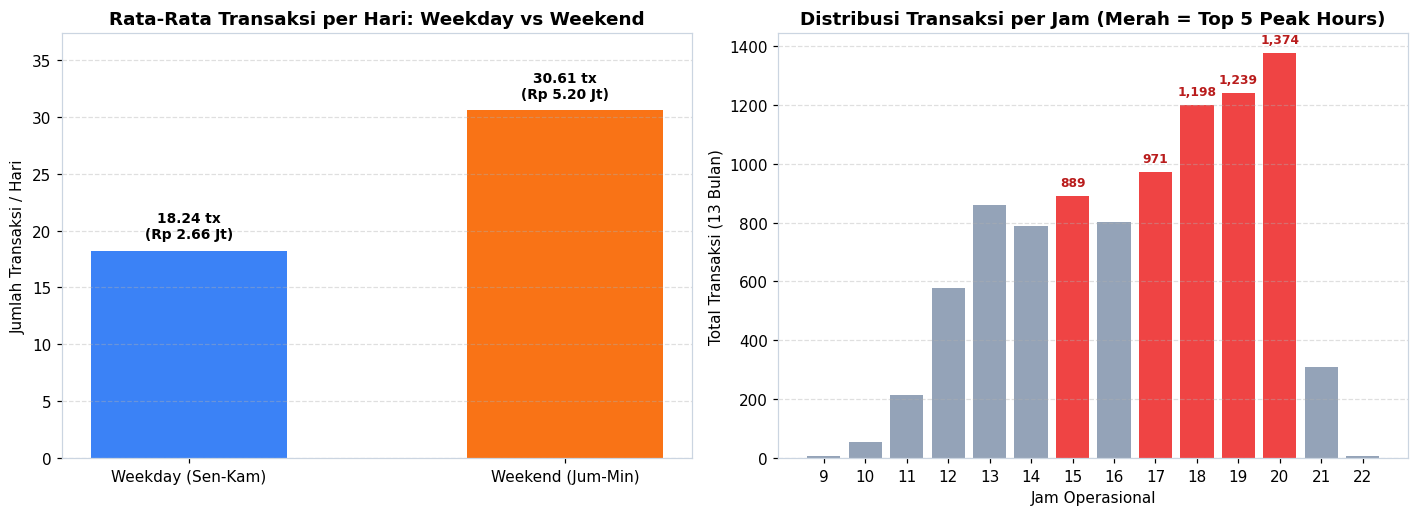

In [3]:
df_tx["dt"] = pd.to_datetime(df_tx["tanggal"])
df_tx["dow"] = df_tx["dt"].dt.dayofweek  # 0=Senin .. 6=Minggu
df_tx["segmen_hari"] = np.where(df_tx["dow"].isin([4, 5, 6]), "Weekend (Jum-Min)", "Weekday (Sen-Kam)")

daily_tx = (
    df_tx.groupby(["tanggal", "segmen_hari"], as_index=False)
    .agg(tx_cnt=("id_transaksi", "count"), omzet=("grand_total", "sum"))
)
seg_summary = daily_tx.groupby("segmen_hari")[["tx_cnt", "omzet"]].mean().round(2)
print("Rata-Rata Harian Weekday vs Weekend:")
print(seg_summary.to_string())

hourly = df_tx["jam"].value_counts().sort_index()
print("\nTop 5 Jam Tersibuk:")
print(df_tx["jam"].value_counts().head(5).to_string())

# Visualisasi bersebelahan
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

order_seg = ["Weekday (Sen-Kam)", "Weekend (Jum-Min)"]
vals_tx = [seg_summary.loc[s, "tx_cnt"] for s in order_seg]
bars0 = axes[0].bar(order_seg, vals_tx, color=["#3B82F6", "#F97316"], width=0.52)
axes[0].set_title("Rata-Rata Transaksi per Hari: Weekday vs Weekend", fontweight="bold")
axes[0].set_ylabel("Jumlah Transaksi / Hari")
axes[0].set_ylim(0, max(vals_tx) * 1.22)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
for b, s in zip(bars0, order_seg):
    omz = seg_summary.loc[s, "omzet"] / 1e6
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{b.get_height():.2f} tx\n(Rp {omz:.2f} Jt)", ha="center", va="bottom", fontsize=9, fontweight="bold")

top_hours = set(df_tx["jam"].value_counts().head(5).index)
bar_colors = ["#EF4444" if h in top_hours else "#94A3B8" for h in hourly.index]
axes[1].bar(hourly.index.astype(str), hourly.values, color=bar_colors)
axes[1].set_title("Distribusi Transaksi per Jam (Merah = Top 5 Peak Hours)", fontweight="bold")
axes[1].set_xlabel("Jam Operasional")
axes[1].set_ylabel("Total Transaksi (13 Bulan)")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
for idx, (h, v) in enumerate(zip(hourly.index, hourly.values)):
    if h in top_hours:
        axes[1].text(idx, v + 25, f"{v:,}", ha="center", va="bottom", fontsize=8, fontweight="bold", color="#B91C1C")

plt.tight_layout()
plt.show()

## 3. Distribusi *Channel* Penjualan & Tren Omzet Bulanan
Memeriksa kontribusi masing-masing kanal penjualan (`Dine-In`, `Takeaway`, aplikasi ojek online) serta lonjakan musiman sepanjang periode Oktober 2025 – Oktober 2026.

Distribusi Channel Penjualan:
channel_penjualan   tx        omzet
          Dine-In 8286 1375492099.5
         Takeaway  422   34618000.0
         GrabFood  265   26432400.0
       ShopeeFood  225   27899000.0
           GoFood   87    9444800.0
            Event   10    5685000.0

Tren Bulanan:
  bulan   tx       omzet
2025-10  747 108031000.0
2025-11  790 107424500.0
2025-12  881 140571500.0
2026-01  813 136779499.5
2026-02  694 105296500.0
2026-03 1112 214614500.0
2026-04  724 108734000.0
2026-05  705 109083400.0
2026-06  721 108349100.0
2026-07  579  89113700.0
2026-08  583  83899500.0
2026-09  446  73214000.0
2026-10  500  94460100.0


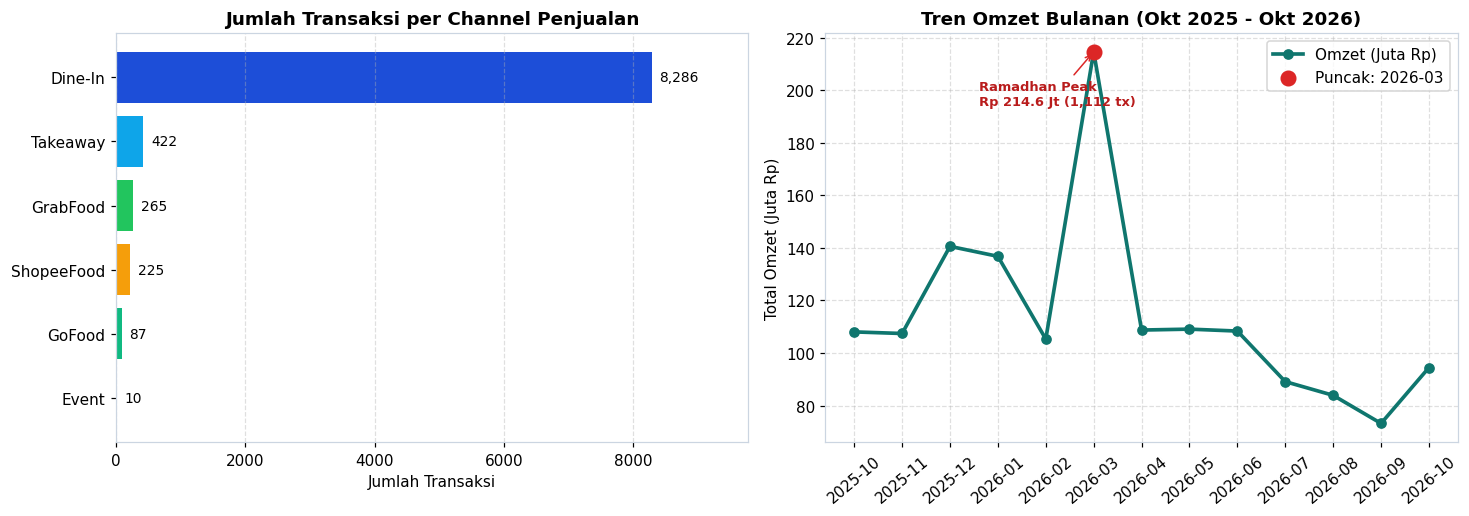

In [4]:
ch = (
    df_tx.groupby("channel_penjualan", as_index=False)
    .agg(tx=("id_transaksi", "count"), omzet=("grand_total", "sum"))
    .sort_values("tx", ascending=True)
)
df_tx["bulan"] = df_tx["tanggal"].str.slice(0, 7)
monthly = (
    df_tx.groupby("bulan", as_index=False)
    .agg(tx=("id_transaksi", "count"), omzet=("grand_total", "sum"))
    .sort_values("bulan")
)

print("Distribusi Channel Penjualan:")
print(ch.sort_values("tx", ascending=False).to_string(index=False))
print("\nTren Bulanan:")
print(monthly.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

ch_colors = ["#64748B", "#10B981", "#F59E0B", "#22C55E", "#0EA5E9", "#1D4ED8"][:len(ch)]
bars_ch = axes[0].barh(ch["channel_penjualan"], ch["tx"], color=ch_colors)
axes[0].set_title("Jumlah Transaksi per Channel Penjualan", fontweight="bold")
axes[0].set_xlabel("Jumlah Transaksi")
axes[0].set_xlim(0, ch["tx"].max() * 1.18)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)
for b in bars_ch:
    w = b.get_width()
    axes[0].text(w + 120, b.get_y() + b.get_height() / 2, f"{int(w):,}", va="center", fontsize=9)

# Time-series tren omzet bulanan (Line Chart valid karena sumbu-X deret waktu kontinyu)
axes[1].plot(monthly["bulan"], monthly["omzet"] / 1e6, marker="o", linewidth=2.4, color="#0F766E", label="Omzet (Juta Rp)")
peak_idx = int(monthly["omzet"].idxmax())
peak_row = monthly.loc[peak_idx]
axes[1].scatter([peak_row["bulan"]], [peak_row["omzet"] / 1e6], color="#DC2626", s=90, zorder=5, label=f"Puncak: {peak_row['bulan']}")
axes[1].annotate(
    f"Ramadhan Peak\nRp {peak_row['omzet']/1e6:.1f} Jt ({int(peak_row['tx']):,} tx)",
    xy=(peak_row["bulan"], peak_row["omzet"] / 1e6),
    xytext=(-75, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="#DC2626"),
    fontsize=8.5,
    fontweight="bold",
    color="#B91C1C",
)
axes[1].set_title("Tren Omzet Bulanan (Okt 2025 - Okt 2026)", fontweight="bold")
axes[1].set_ylabel("Total Omzet (Juta Rp)")
axes[1].tick_params(axis="x", rotation=40)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 4. Evaluasi Dampak Konsumsi Internal (`CREW ALES`, `OWNER`, dll.)
Meskipun transaksi internal sering dicatat dengan diskon 100%, bahan baku dapur tetap berkurang secara fisik. Kita hitung berapa nilai HPP pemakaian BoM dari transaksi eksternal vs internal.

Eksternal (Pelanggan)       : Rp    271,783,071 (97.90%)
Internal (Crew/Owner/Ops)   : Rp      5,827,129 (2.10%)


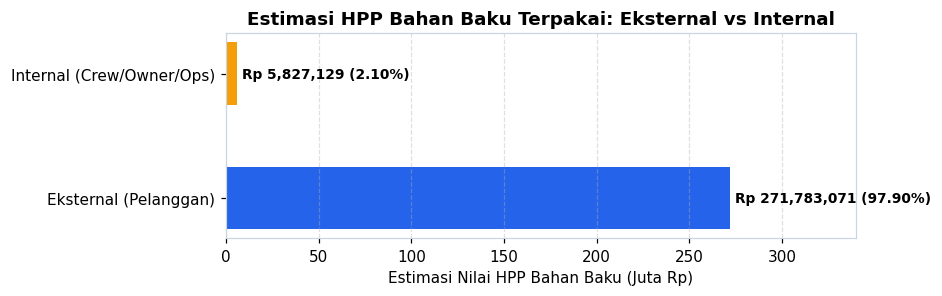

In [5]:
merged = df_items.merge(df_tx[["id_transaksi", "is_internal_order"]], on="id_transaksi", how="left")
merged_bom = merged.dropna(subset=["id_menu_resep"]).merge(
    df_bom, left_on="id_menu_resep", right_on="id_menu", how="inner"
)
merged_bom["used_cost"] = merged_bom["qty"] * merged_bom["estimasi_biaya_bahan"]

cost_by_type = (
    merged_bom.groupby("is_internal_order")["used_cost"]
    .sum()
    .rename(index={0: "Eksternal (Pelanggan)", 1: "Internal (Crew/Owner/Ops)"})
)
total_bom_cost = float(cost_by_type.sum())
for k, v in cost_by_type.items():
    print(f"{k:28s}: Rp {v:14,.0f} ({v / total_bom_cost * 100:.2f}%)")

fig, ax = plt.subplots(figsize=(8.5, 2.8))
bars_int = ax.barh(cost_by_type.index.tolist(), (cost_by_type / 1e6).values, color=["#2563EB", "#F59E0B"], height=0.5)
ax.set_title("Estimasi HPP Bahan Baku Terpakai: Eksternal vs Internal", fontweight="bold")
ax.set_xlabel("Estimasi Nilai HPP Bahan Baku (Juta Rp)")
ax.set_xlim(0, (cost_by_type.max() / 1e6) * 1.25)
ax.grid(axis="x", linestyle="--", alpha=0.4)
for b, raw_v in zip(bars_int, cost_by_type.values):
    ax.text(b.get_width() + 3, b.get_y() + b.get_height() / 2, f"Rp {raw_v:,.0f} ({raw_v / total_bom_cost * 100:.2f}%)", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Top 15 Bahan Baku Penguras Biaya & *Daily Burn Rate* (395 Hari Aktif)
Menghitung total konsumsi dan rata-rata pemakaian harian (`Daily Burn Rate`) untuk seluruh bahan aktif pada menu terpetakan selama 395 hari operasional.

    nama_bahan satuan_dasar  total_pemakaian  burn_rate_395d   total_hpp
   DAGING SAPI         gram      270860.0000          685.72 28440300.00
 CHICKEN KATSU         gram      286420.0000          725.11 27209900.00
          SOYU           ml      215440.0000          545.42 12926400.00
         TELUR          pcs        6872.2792           17.40 10464569.74
  BUMBU MINYAK         gram       98200.0000          248.61  9329000.00
           MIE         gram      557060.0000         1410.28  7798840.00
SANQUIK MANGGA           ml      103330.0000          261.59  7380720.79
  BUMBU KERING         gram      109282.0000          276.66  6994048.00
         BERAS         gram      499450.0000         1264.43  6492850.00
       VANILLA         gram       47250.0000          119.62  5670000.00
 SANQUIK LEMON           ml       74550.0000          188.73  5421821.19
   AIR MINERAL          pcs        3154.0000            7.98  4731000.00
   NORI LEMBAR          pcs        1332.0000       

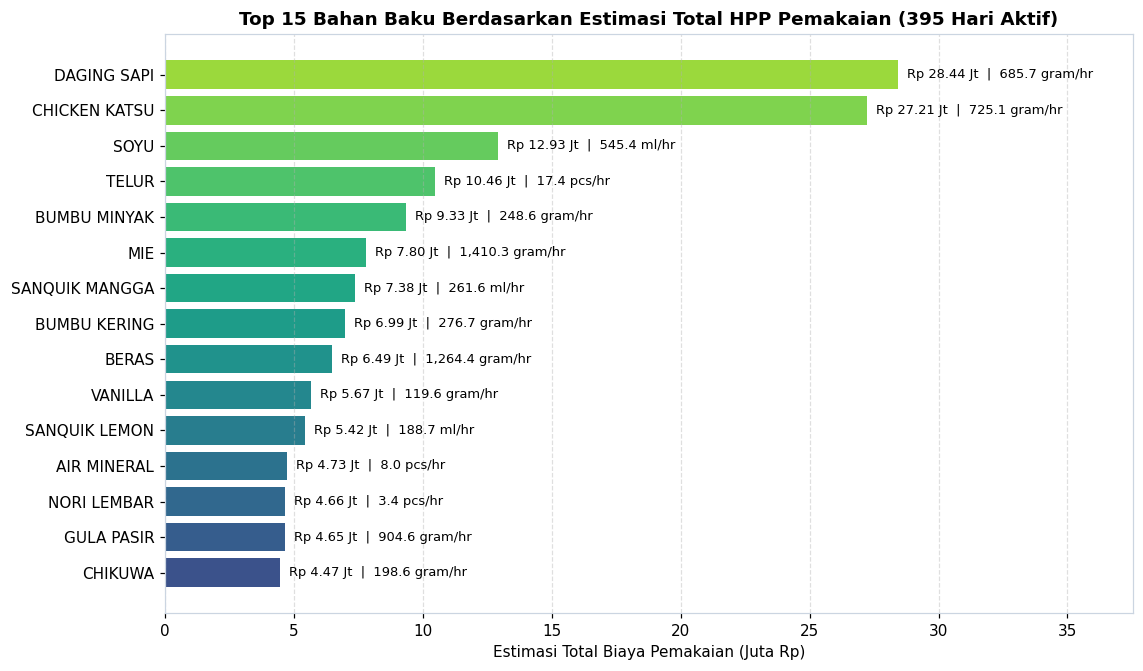

In [6]:
top_ing = (
    df_usage.groupby(["id_bahan", "nama_bahan", "satuan_dasar"], as_index=False)
    .agg(total_pemakaian=("total_pemakaian", "sum"), total_hpp=("estimasi_hpp", "sum"))
    .sort_values("total_hpp", ascending=False)
)
top_ing["burn_rate_395d"] = (top_ing["total_pemakaian"] / 395.0).round(2)
top15 = top_ing.head(15).copy()
print(top15[["nama_bahan", "satuan_dasar", "total_pemakaian", "burn_rate_395d", "total_hpp"]].to_string(index=False))

top15_plot = top15.sort_values("total_hpp", ascending=True)
fig, ax = plt.subplots(figsize=(10.5, 6.2))
palette = plt.cm.viridis(np.linspace(0.25, 0.85, len(top15_plot)))
bars15 = ax.barh(top15_plot["nama_bahan"], top15_plot["total_hpp"] / 1e6, color=palette)
ax.set_title("Top 15 Bahan Baku Berdasarkan Estimasi Total HPP Pemakaian (395 Hari Aktif)", fontweight="bold")
ax.set_xlabel("Estimasi Total Biaya Pemakaian (Juta Rp)")
ax.set_xlim(0, (top15_plot["total_hpp"].max() / 1e6) * 1.32)
ax.grid(axis="x", linestyle="--", alpha=0.4)
for b, (_, r) in zip(bars15, top15_plot.iterrows()):
    lbl = f"Rp {r['total_hpp']/1e6:.2f} Jt  |  {r['burn_rate_395d']:,.1f} {r['satuan_dasar']}/hr"
    ax.text(b.get_width() + 0.35, b.get_y() + b.get_height() / 2, lbl, va="center", fontsize=8.5)

plt.tight_layout()
plt.show()

## 6. Verifikasi Dataset Siap-AI (`output/data_for_ai/`) & *Anti-Data Leakage* untuk Tim AE
Di tahap ini, data pemakaian harian dari `v_pemakaian_bahan_harian` telah direindex ke kalender penuh 396 hari $\times$ 161 bahan aktif BoM (total **63.756 baris**), dilengkapi fitur kalender dan lag/rolling kausal (`shift(1)`), serta dibagi berbasis waktu tanpa tumpang tindih:
- **Train:** `2025-10-01` s.d. `2026-09-30` (365 hari)
- **Test:** `2026-10-01` s.d. `2026-10-31` (31 hari)

Full rows : 63,756 (396 hari x 161 bahan)
Train rows: 58,765 (2025-10-01 s.d. 2026-09-30)
Test rows : 4,991 (2026-10-01 s.d. 2026-10-31)
Label     : PRIMARY_NUTACLOUD_X_BOM2018_PARTIAL_59PCT

Contoh 5 baris fitur untuk DAGING SAPI (periode test):
   tanggal  nama_bahan  total_pemakaian  is_weekend  is_payday_window  lag_1  lag_7  rolling_mean_7
2026-10-01 DAGING SAPI            110.0           0                 1  260.0  450.0        535.7143
2026-10-02 DAGING SAPI            150.0           1                 1  110.0  230.0        487.1429
2026-10-03 DAGING SAPI           1010.0           1                 1  150.0 1260.0        475.7143
2026-10-04 DAGING SAPI           1530.0           1                 1 1010.0 1050.0        440.0000
2026-10-05 DAGING SAPI            290.0           0                 1 1530.0  150.0        508.5714


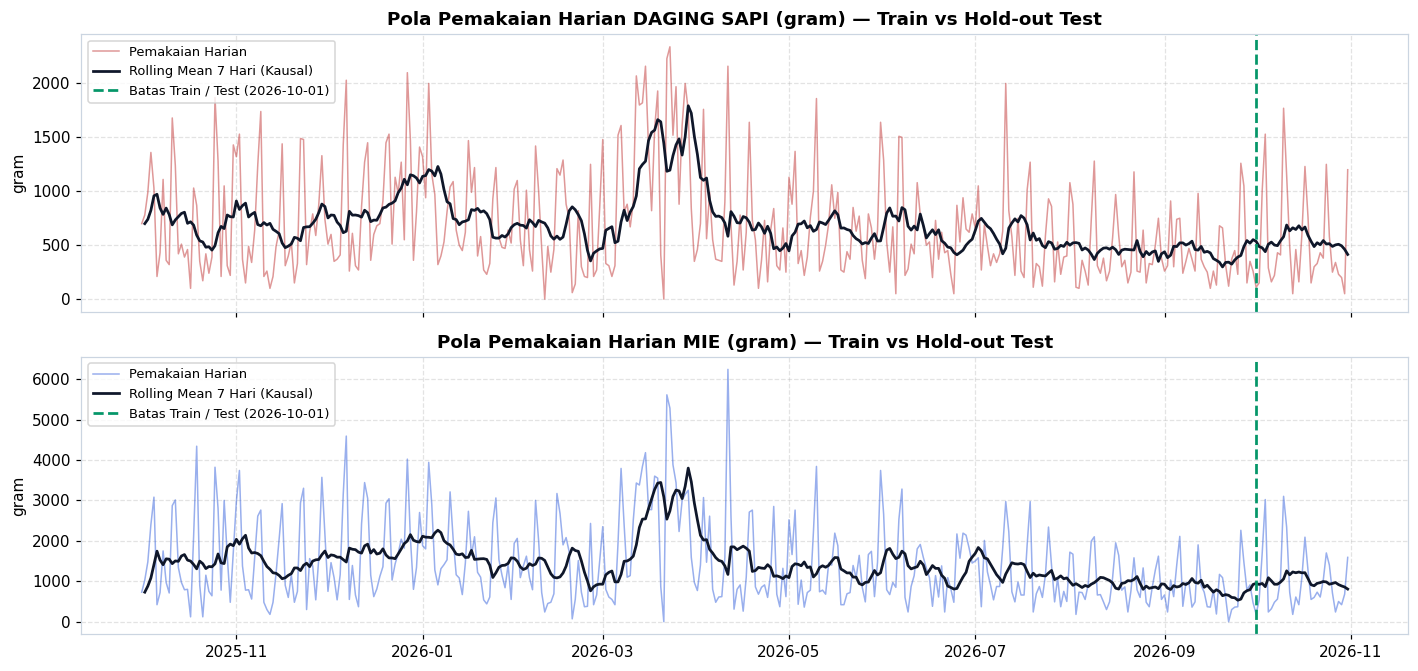

In [7]:
train_df = pd.read_csv(AI_DIR / "train_daily_usage.csv")
test_df = pd.read_csv(AI_DIR / "test_daily_usage.csv")
full_df = pd.read_csv(AI_DIR / "daily_usage_full_features.csv")

assert train_df["tanggal"].max() < test_df["tanggal"].min(), "Terdeteksi tumpang tindih tanggal train/test!"
print(f"Full rows : {len(full_df):,} ({full_df['tanggal'].nunique()} hari x {full_df['id_bahan'].nunique()} bahan)")
print(f"Train rows: {len(train_df):,} ({train_df['tanggal'].min()} s.d. {train_df['tanggal'].max()})")
print(f"Test rows : {len(test_df):,} ({test_df['tanggal'].min()} s.d. {test_df['tanggal'].max()})")
print(f"Label     : {full_df['data_source_label'].iloc[0]}")
print("\nContoh 5 baris fitur untuk DAGING SAPI (periode test):")
cols_show = ["tanggal", "nama_bahan", "total_pemakaian", "is_weekend", "is_payday_window", "lag_1", "lag_7", "rolling_mean_7"]
print(test_df[test_df["nama_bahan"] == "DAGING SAPI"][cols_show].head(5).to_string(index=False))

# Visualisasi deret waktu pemakaian aktual + garis batas split Train vs Test
fig, axes = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True)
for ax, ing_name, color in [(axes[0], "DAGING SAPI", "#B91C1C"), (axes[1], "MIE", "#1D4ED8")]:
    sub = full_df[full_df["nama_bahan"] == ing_name].sort_values("tanggal").copy()
    sub["dt"] = pd.to_datetime(sub["tanggal"])
    ax.plot(sub["dt"], sub["total_pemakaian"], alpha=0.45, linewidth=1.0, color=color, label="Pemakaian Harian")
    ax.plot(sub["dt"], sub["rolling_mean_7"], linewidth=1.8, color="#0F172A", label="Rolling Mean 7 Hari (Kausal)")
    ax.axvline(pd.Timestamp("2026-10-01"), color="#059669", linestyle="--", linewidth=1.8, label="Batas Train / Test (2026-10-01)")
    satuan = sub["satuan_dasar"].iloc[0]
    ax.set_title(f"Pola Pemakaian Harian {ing_name} ({satuan}) — Train vs Hold-out Test", fontweight="bold")
    ax.set_ylabel(satuan)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

### Q&A
1. **Bagaimana pola trafik *weekday* vs *weekend* dan kapan *peak hours* operasional?**  
   Rata-rata transaksi pada **Weekend (Jumat–Minggu)** mencapai **30,61 transaksi/hari** (**Rp 5.200.040/hari**), melonjak **+67,8% transaksi** (+95,6% omzet) dibandingkan **Weekday (Senin–Kamis)** sebesar **18,24 transaksi/hari** (**Rp 2.658.250/hari**). Puncak pesanan terjadi pukul **17:00–20:59** dengan puncaknya pada pukul **20:00 (1.374 transaksi)**.
2. **Bagaimana distribusi *channel* penjualan dan tren bulanannya?**  
   `Dine-In` mendominasi (**8.286** transaksi), diikuti `Takeaway` (**422**), `GrabFood` (**265**), `ShopeeFood` (**225**), `GoFood` (**87**), dan `Event` (**10**). Tren bulanan melonjak tajam pada **Maret 2026** sebesar **1.112 transaksi / Rp 214.614.500** saat periode Ramadhan, dan tutup 1 hari pada **21 Maret 2026** (Idul Fitri).
3. **Apakah transaksi internal signifikan terhadap konsumsi stok bahan baku?**  
   Pada menu terpetakan BoM, **787 transaksi internal** menghabiskan bahan senilai **Rp 5.827.129** (~**2,10%** dari total estimasi HPP BoM Rp 277.610.200). Karena memotong fisik dapur secara nyata, transaksi internal tetap wajib dimasukkan ke pemotongan stok.
4. **Bahan baku apa saja yang paling krusial untuk dipantau?**  
   Prioritas biaya & *burn rate* tertinggi meliputi `DAGING SAPI` (**685,72 g/hari** | Rp 28,44 Jt), `CHICKEN KATSU` (**725,11 g/hari** | Rp 27,21 Jt), `SOYU` (**545,42 ml/hari** | Rp 12,93 Jt), `TELUR` (**17,40 pcs/hari** | Rp 10,46 Jt), `MIE` (**1.410,28 g/hari** | Rp 7,80 Jt), dan `BERAS` (**1.264,43 g/hari** | Rp 6,49 Jt).

### Data Analysis Key Findings
- Seluruh **9.295 transaksi** memiliki total omzet `grand_total` **Rp 1.479.571.300** (eksternal **Rp 1.443.778.300**) tanpa nilai null pada kolom kunci.
- Cakupan resep 2018 saat ini menghubungkan **34.289 / 58.102 porsi (59,0%)** dan mengaktifkan **123 / 178 bahan baku** di data penjualan.
- Dataset AI di `output/data_for_ai/` menyediakan **63.756 baris** (396 hari $\times$ 161 bahan BoM) dengan split bebas *data leakage*: **58.765 baris train** (`2025-10-01` s.d. `2026-09-30`) dan **4.991 baris test** (`2026-10-01` s.d. `2026-10-31`).

### Insights or Next Steps
- Terapkan parameter `buffer_waste_pct` (3%–5%) di `src/bom_engine.py` dan *Safety Stock* berbasis variasi *weekend* di `src/stock_analytics.py` untuk mengantisipasi lonjakan Jumat–Minggu dan periode Ramadhan.
- Serahkan `train_daily_usage.csv`, `test_daily_usage.csv`, dan `DATA_DICTIONARY.md` ke tim **AE (Ayunda & Faris)** untuk pelatihan model ML *forecasting*, serta lengkapi Top 30 resep menu baru setelah mendapat balasan dari Owner.